## **Exploratory Data Analysis (EDA): Rokuten Viki Dramas And Movies**

### **Project Overview**

This project focuses on conducting a comprehensive Exploratory Data Analysis (EDA) on Rokuten Viki dataset. Rokuten Viki is a premier global video streaming platform specializing in Asian entertainment, featuring a vast collection of dramas and movies from South Korea, China, Japan, Taiwan and other regions. The goal of this analysis is to uncover trends in content availability, evaluate user engagement, explore genre distributions, and understand the characteristics that define popular titles on the platform.

### **Dataset Description**

This dataset was created to list all shows available on Rakuten Viki streaming, and analyze the data to find interesting facts. This data was acquired in May 2022 containing data available in the United States.

This dataset has two files containing the titles (titles.csv) and the cast (credits.csv) for the title.

The dataset (titles.csv) contains +1800 unique titles on Rakuten Viki with 15 columns and the dataset (credits.csv) contains +19000 unique casts. The detailed description is provided as we proceed further.

### Note: 
To keep the workflow modular and visually clear, libraries and dependencies are importeddynamically throughout the notebook in the specific sections where they are utilized, rather that all at once in the initial cell.

In [1]:
# Importing Required Libraries and Dependencies

import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import kagglehub


In [2]:
# Download latest version of the dataset from Kaggle and store it in a local directory
path = kagglehub.dataset_download("victorsoeiro/rakuten-tv-dramas-and-movies")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Snehamayee\.cache\kagglehub\datasets\victorsoeiro\rakuten-tv-dramas-and-movies\versions\1


In [3]:
# print all the files in the dataset
print("Files in the dataset folder:")
print(os.listdir(path))

Files in the dataset folder:
['credits.csv', 'titles.csv']


In [4]:
# Verify and establish your target local project directory
target_raw_dir = "../data/raw"
os.makedirs(target_raw_dir, exist_ok=True)

# Authomatically copy the CSV files from cache into your project directory
for file_name in ['titles.csv', 'credits.csv']:
    source_file_path = os.path.join(path, file_name)
    destination_file_path = os.path.join(target_raw_dir, file_name)
    shutil.copy(source_file_path, destination_file_path)
    print(f"Copied {file_name} successfully into local project folder: {target_raw_dir}/")

# Load the CSV files into pandas DataFrames
df_titles = pd.read_csv("../data/raw/titles.csv")
df_credits = pd.read_csv("../data/raw/credits.csv")

print(f"\n--- Dataframes successfully loaded ---")
print(f"Titles DataFrame shape: {df_titles.shape}")
print(f"Credits DataFrame shape: {df_credits.shape}")

Copied titles.csv successfully into local project folder: ../data/raw/
Copied credits.csv successfully into local project folder: ../data/raw/

--- Dataframes successfully loaded ---
Titles DataFrame shape: (1904, 15)
Credits DataFrame shape: (19466, 5)


In [5]:
df_titles.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts299859,Serendipity,SHOW,NaN,1973,NaN,39,[],['XX'],1.0,tt8912714,NaN,NaN,NaN,NaN
1,ts43055,Entertainment Weekly,SHOW,This program -- one of our viewers’ favorites ...,1984,NaN,60,['reality'],['KR'],1.0,tt7782444,NaN,NaN,4.729,8.5
2,tm21196,Il Mare,MOVIE,"In the year 1999, a young woman leaves her qua...",2000,NaN,105,"['fantasy', 'scifi', 'romance', 'drama', 'docu...",['KR'],NaN,tt0282599,7.5,8777.0,10.413,7.5
3,tm8809,Fight Back to School,MOVIE,Star Chow is about to be kicked out of the Roy...,1991,NaN,100,"['comedy', 'action', 'romance']",['HK'],NaN,tt0103045,7.0,4021.0,5.616,6.6
4,ts39072,Inkigayo,SHOW,The program is a weekly music show that featur...,1998,NaN,69,"['reality', 'music']",['KR'],2.0,tt6050846,5.7,9.0,2.154,9.0


In [6]:
df_titles.info()                                        

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1904 non-null   object 
 1   title                 1904 non-null   object 
 2   type                  1904 non-null   object 
 3   description           1824 non-null   object 
 4   release_year          1904 non-null   int64  
 5   age_certification     273 non-null    object 
 6   runtime               1904 non-null   int64  
 7   genres                1904 non-null   object 
 8   production_countries  1904 non-null   object 
 9   seasons               1470 non-null   float64
 10  imdb_id               1456 non-null   object 
 11  imdb_score            1370 non-null   float64
 12  imdb_votes            1370 non-null   float64
 13  tmdb_popularity       1842 non-null   float64
 14  tmdb_score            1505 non-null   float64
dtypes: float64(5), int64(

### Data Description:
#### df_titles
The dataset (df_titles) has the following attributes:

1. `id` : A unique alphanumeric identifier assigned to each movie or show in the dataset.

2. `title` : The official name or title of the movie or drama series.
3. `type` : Specifies whether the content is a standalone movie or a multi-episode show.
4. `description` : A brief text summary outlining the plot or synopsis of the title.
5. `release_year` : The calender year when the movie or show was originally released.
6. `age_certification` : The official maturityrating assigned to the content (e.g., PG, TV-MA), showing `NaN` if unrated.
7. `runtime` : The total duration of the movie or the average episode length of the show in minutes.
8. `genres` : A list of categories or genres that describe the content's style (e.g., ['romance', 'drama']).
9. `production_countries` : A list containing the country codes where the movie or show was produced (e.g., [KR] for South Korea).
10. `seasons` : The total number of seasons available for a show, which appreas as `NaN` for movies.
11. `imdb_id` : The unique identifier code for the title on the external IMDb database website.
12. `imdb_score` : The average user rating of the title on IMDb, scored on a scale from 1 to 10.
13. `imdb_votes` : The total count of individual user ratings submitted for this specific title on IMDb.
14. `tmdb_popularity` : A relative metric score indicating how popular the title currently is on the TMDb platform.
15. `tmdb_score` : The average user rating given to the show on the TMDb platform.


### Note:
In this notebook we will only be using **df_titles** for **Exploratory Data Analysis**

Checking for Duplicates:


In [7]:
print(f"df_titles has {df_titles.duplicated().sum()} duplicate rows." )

df_titles has 0 duplicate rows.


Checking for Nulls:

In [8]:
df_titles.isnull().sum()

id                         0
title                      0
type                       0
description               80
release_year               0
age_certification       1631
runtime                    0
genres                     0
production_countries       0
seasons                  434
imdb_id                  448
imdb_score               534
imdb_votes               534
tmdb_popularity           62
tmdb_score               399
dtype: int64

In [10]:
# Let's look at the descriptive statistics of the numerical columns in the df_titles DataFrame before we proceed with further data cleaning and analysis.

df_titles[['imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']].describe()

,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,1370.000000,1370.000000,1842.000000,1505.000000
mean,7.086058,1296.285401,8.718212,7.330764
std,1.011513,7213.066580,15.234642,1.423521
min,1.400000,5.000000,0.069592,1.000000
25%,6.500000,48.000000,2.128000,6.600000
50%,7.300000,188.500000,4.616500,7.500000
75%,7.800000,769.500000,9.789750,8.200000
max,9.600000,208644.000000,381.236000,10.000000


### Handling missing numerical values

- The mean and median(50%) for imdb_score are almost identical and the std is also very low. This means the scores are distributed symmetrically without heavy outliers dragging them in one direction, so using the `mean` is prefered to fill the nulls . And same goes for tmdb_score as well.
- But for imdb_votes and tmdb_popularity the data is incredibly skewed. Here (suppose for imdb_votes) the mean(~ 1296) is much higher than the median(188.5) and the std(7213) also indicated high spread hinting at heavy outliers. Thus, `median` is prefered to fill the nulls here. 

### Handling Missing Text Descriptions
The dataset contains 80 missing records within the 'description' column.

Rather than dropping these records or filling them with artificial text placeholders (like "Unknown"), we explicitely fill them with empty strings ('""'). 
This data cleaning chioce ensures that:
1. **Catalog Preservation:** We maintain a 100% complete production catalog for downstream consumption.
2. **NLP Safety:** It preserves future text vectorization models (like TF=IDF or CounterVectorizer)
3. **Hybrid Robustness:** It allows downstream recommendationengines to seamlessly leverage the clean 'genres' dimension for these 80 titles even in the absence of a description summary.


In [11]:
# Check the unique values in the 'type' column sothat we can use proper mapping for filling missing values in the 'seasons' column.
print(df_titles['type'].unique())

['SHOW' 'MOVIE']


In [12]:
# 1. Fill missing values in the 'age_certification', 'imdb_id' columns with  placeholder values.
df_titles['age_certification'] = df_titles['age_certification'].fillna("Not rated")                         
df_titles['imdb_id'] = df_titles['imdb_id'].fillna("Unknown") 

# 2. Fill missing values in 'description' column with empty string
df_titles['description'] = df_titles['description'].fillna("")


# 3. Fill seasons as 0 for MOVIE and 1 for SHOW
df_titles['seasons'] = df_titles['seasons'].fillna(df_titles['type'].map({'MOVIE': 0, 'SHOW': 1}))



# 4. Fill scores using the MEAN
df_titles['imdb_score'] = df_titles['imdb_score'].fillna(df_titles['imdb_score'].mean())
df_titles['tmdb_score'] = df_titles['tmdb_score'].fillna(df_titles['imdb_score'].mean())      


# 5. Fill votes and popularity using the MEDIAN
df_titles['imdb_votes'] = df_titles['imdb_votes'].fillna(df_titles['imdb_votes'].median())
df_titles['tmdb_popularity'] = df_titles['tmdb_popularity'].fillna(df_titles['tmdb_popularity'].median()) 


In [13]:
df_titles.isnull().sum()

id                      0
title                   0
type                    0
description             0
release_year            0
age_certification       0
runtime                 0
genres                  0
production_countries    0
seasons                 0
imdb_id                 0
imdb_score              0
imdb_votes              0
tmdb_popularity         0
tmdb_score              0
dtype: int64

#### Exploding the **genres** and **production_countries** columns

In [14]:
print(df_titles['genres'].unique())

['[]' "['reality']"
 "['fantasy', 'scifi', 'romance', 'drama', 'documentation']"
 "['comedy', 'action', 'romance']" "['reality', 'music']"
 "['action', 'fantasy']" "['comedy', 'romance']" "['romance', 'comedy']"
 "['comedy', 'action', 'crime']" "['comedy', 'drama', 'romance']"
 "['fantasy', 'drama', 'romance']"
 "['comedy', 'drama', 'romance', 'action']"
 "['thriller', 'drama', 'action', 'crime']"
 "['crime', 'drama', 'thriller', 'action', 'european']"
 "['drama', 'comedy', 'romance']"
 "['scifi', 'comedy', 'drama', 'fantasy', 'romance']"
 "['comedy', 'reality']" "['drama', 'comedy', 'music', 'romance']"
 "['drama', 'comedy', 'history', 'romance']"
 "['drama', 'romance', 'history']" "['action', 'drama', 'history']"
 "['drama', 'romance']" "['documentation', 'history']"
 "['drama', 'history', 'romance']" "['drama']"
 "['comedy', 'drama', 'romance', 'fantasy']" "['drama', 'thriller']"
 "['comedy', 'drama', 'animation', 'romance', 'scifi', 'fantasy']"
 "['action', 'drama', 'romance']" "['

In [15]:
df_titles["genres"] = df_titles["genres"].str.replace(r'[\[\]"\']', '', regex=True).str.split(', ')

In [16]:
print(df_titles['genres'].iloc[3])

['comedy', 'action', 'romance']


In [17]:
print(type(df_titles['genres'].iloc[3]))

<class 'list'>


In [18]:
print(type(df_titles['genres'].iloc[3][0]))

<class 'str'>


In [19]:
df_titles["production_countries"] = df_titles["production_countries"].str.replace(r'[\[\]"\']', '', regex=True).str.split(', ')

In [20]:
df_titles["production_countries"].iloc[4]

['KR']

In [21]:
df_genres_exploded = df_titles.explode("genres")
df_countries_exploded = df_titles.explode("production_countries")

In [22]:
df_genres_exploded["genres"].value_counts()

genres
drama            1260
romance           816
comedy            628
action            268
fantasy           237
thriller          195
scifi             149
crime             136
                  126
history           111
reality            92
family             52
documentation      42
horror             41
music              38
war                27
sport              24
european           13
animation          11
western             1
Name: count, dtype: int64

In [23]:
df_countries_exploded["production_countries"].value_counts()

production_countries
KR    1020
CN     473
       132
JP     114
TW      75
HK      38
US      30
TH      17
VN       8
CA       5
GB       5
XX       4
FR       4
AU       3
DE       2
IT       2
NC       2
PH       2
MY       2
BE       1
IE       1
MO       1
TR       1
BR       1
Name: count, dtype: int64

In [24]:
print("Empty strings:", (df_genres_exploded["genres"] == '').sum())
print("Just spaces", df_genres_exploded["genres"].str.isspace().sum())


Empty strings: 126
Just spaces 0


In [25]:
df_genres_exploded = df_genres_exploded[df_genres_exploded["genres"].str.strip() != '']

In [26]:
print("Empty strings:", (df_genres_exploded["genres"] == '').sum())


Empty strings: 0


In [27]:
print("Empty strings:", (df_countries_exploded["production_countries"] == '').sum())
print("Just spaces", df_countries_exploded["production_countries"].str.isspace().sum())


Empty strings: 132
Just spaces 0


In [28]:
df_countries_exploded = df_countries_exploded[df_countries_exploded["production_countries"].str.strip() != '']

In [29]:
print("Empty strings:", (df_countries_exploded["production_countries"] == '').sum())


Empty strings: 0



# Exploratory data analysis to find interesting insights

### Format Dominance (Movies vs. TV Shows)

In [30]:
type_counts = df_titles['type'].value_counts()
type_percentages = df_titles['type'].value_counts(normalize=True) * 100

print("--- Raw Counts ---")
print(type_counts)
print("\n--- Percentage Split ---")
print(type_percentages.round(2).astype(str) + " %")

--- Raw Counts ---
type
SHOW     1470
MOVIE     434
Name: count, dtype: int64

--- Percentage Split ---
type
SHOW     77.21 %
MOVIE    22.79 %
Name: proportion, dtype: object


**Visualization (Bar Plot) of SHOW vs. MOVIE Types**

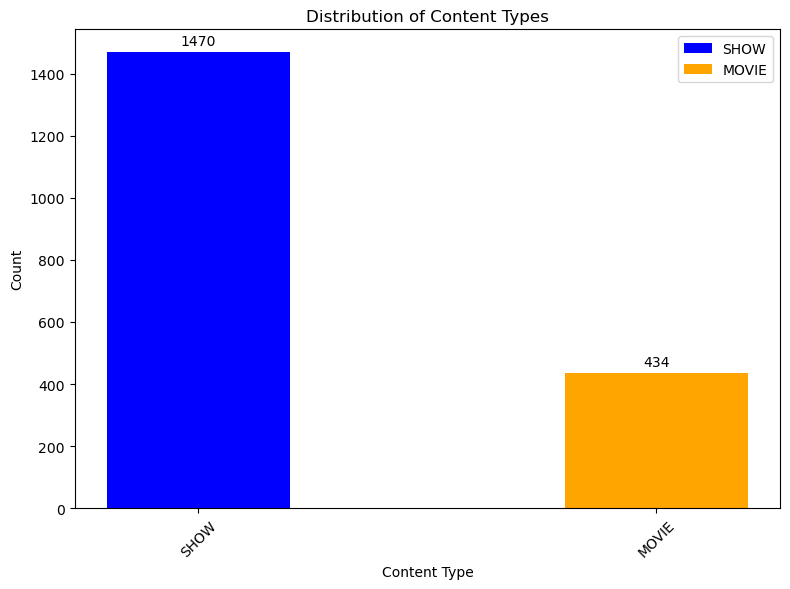

In [31]:
plt.figure(figsize=(8, 6))  

bars=plt.bar(type_counts.index, type_counts.values, color=['blue', 'orange'], width=0.4)   

plt.bar_label(bars, padding=3)

plt.xlabel('Content Type')  
plt.ylabel('Count')  
plt.title('Distribution of Content Types')  
plt.xticks(rotation=45) 

plt.legend(bars.patches, ['SHOW', 'MOVIE'], loc='upper right')
plt.tight_layout()  
plt.show()  

- The Bar Plot above clearly shows `SHOWS` are the most watched content type on the Rokuten Viki platform.

Let's see how both types(`SHOWS` and `MOVIES`) evolve over years(`release_year`)

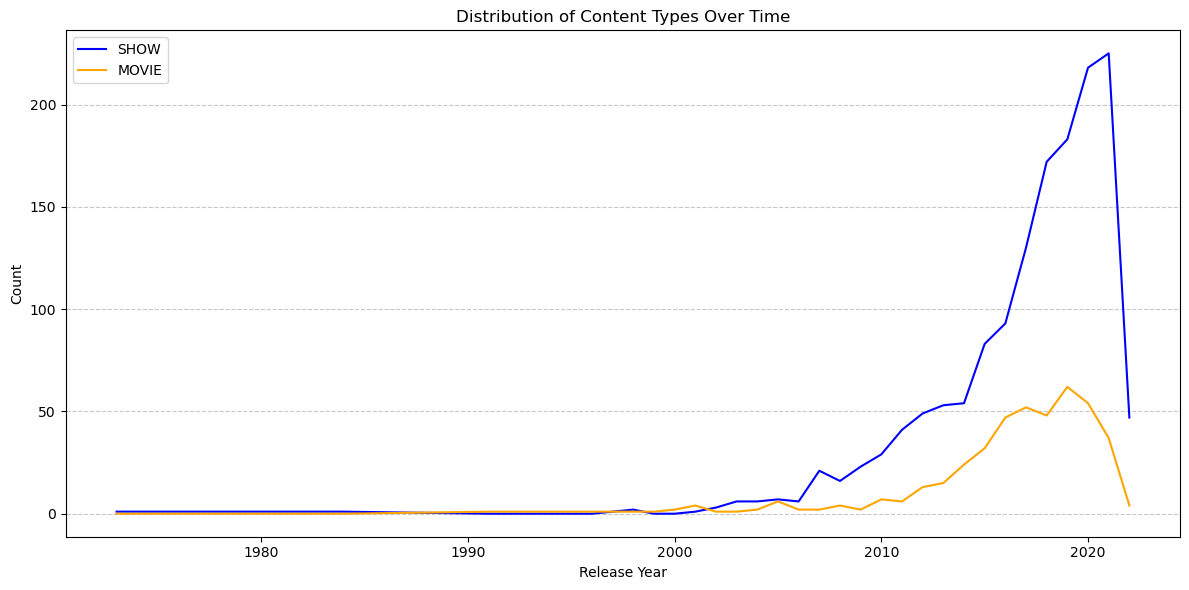

In [32]:
# 1. Let's first group the data by year and type, and then count the number of titles in each group. 
# This will give us a clear picture of how the number of titles has changed over time for both movies and shows. 

yearly_type_counts = df_titles.groupby(['release_year', 'type']).size().unstack(fill_value=0)

# Plot lines for both types
plt.figure(figsize=(12, 6))
plt.plot(yearly_type_counts.index, yearly_type_counts['SHOW'], label='SHOW', color='blue')
plt.plot(yearly_type_counts.index, yearly_type_counts['MOVIE'], label='MOVIE', color='orange')
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.title('Distribution of Content Types Over Time')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

- The above plot shows both the types started to grow from the year 2000.
- This indicates a massive industry-wide paradigm shift at the turn of the millennium, driven by the global expansion of the Korean Wave(Hallyu), incresed production budgets, and the lifting of media censorship laws.
- While both mediums expanded, the growth of `SHOWS` outperforms the growth of `MOVIES` because serialized, episodic content is fundamentally better suited for modern internet streaming platforms (like Rakuten Viki and Netflix).
- Multi-episode dramas generate much higher user engagement, foster global binge-watching culture, and offer significantly more screen time for character development and product monetization than standalone films.

### **Genres Dominance**

In [33]:
genres_counts = df_genres_exploded['genres'].value_counts()
genres_percentages = df_genres_exploded['genres'].value_counts(normalize=True) * 100

In [34]:
print("--- Raw Counts of Genres ---")
print(genres_counts)
print("\n--- Percentage Split of Genres ---")
print(genres_percentages.round(2).astype(str)[:3] + " %")

--- Raw Counts of Genres ---
genres
drama            1260
romance           816
comedy            628
action            268
fantasy           237
thriller          195
scifi             149
crime             136
history           111
reality            92
family             52
documentation      42
horror             41
music              38
war                27
sport              24
european           13
animation          11
western             1
Name: count, dtype: int64

--- Percentage Split of Genres ---
genres
drama      30.43 %
romance    19.71 %
comedy     15.17 %
Name: proportion, dtype: object


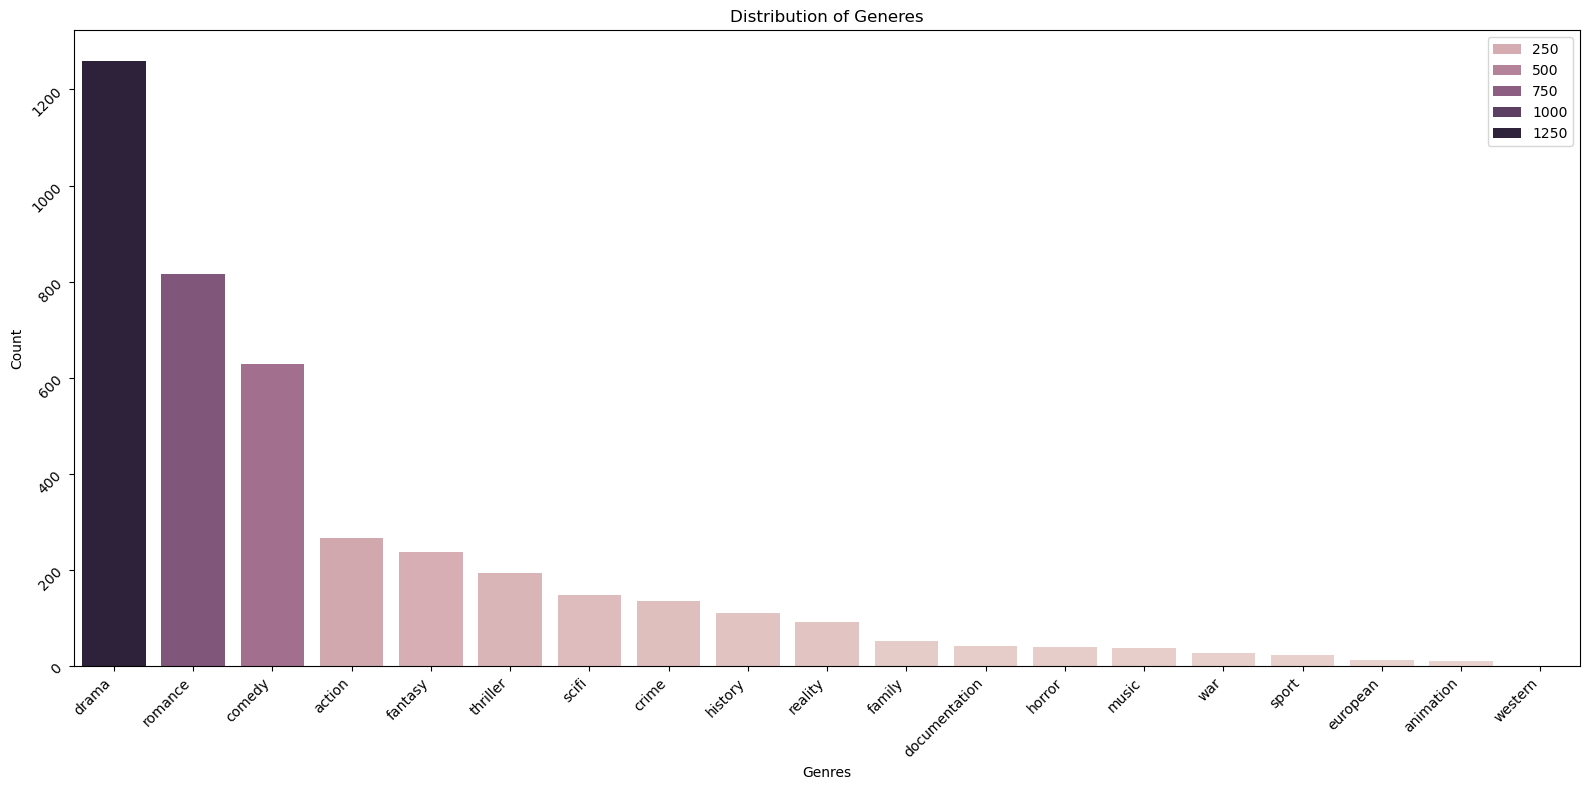

In [35]:
plt.figure(figsize=(16, 8))  

bars=sb.barplot(x=genres_counts.index, y=genres_counts.values, hue=genres_counts.values, legend=True)   

plt.xlabel('Genres')  
plt.ylabel('Count')  
plt.title('Distribution of Generes') 
plt.xticks(rotation=45, ha='right') 
plt.yticks(rotation=45, ha='right') 


plt.tight_layout()  
plt.show()  

#### **Key Insights**
- The platform is heavily dominated by **drama**, **romance** and **comedy**, which makes up over 65% of titles
- **Drama** is the single largest genre with over **1,200** titles, followed closely by Romance and Comedy.

## **Production Country Dominance**

- The country codes used in the dataset (df_titles) are **ISO 3166-1 alpha-2 country codes**, which are standard two-letter codes used internationally to represent countries and territories.

KR : South Korea  
CN : China  
JP : JAPAN  
TW : TAIWAN  
HK : HONG KONG  
US : UNITED STATES    
CA : CANADA  
GB : GREAT BRITAIN / UNITED KINGDOM    
FR : FRANCE  
DE : GERMANY  
IT : ITALY  
BE : BELGIUM  
IE : IRELAND  
TH : THAILAND   
VN : VIETNAM  
PH : PHILIPPINES  
MY : MALAYSIA  
AU : AUSTRALIA  
NC : NEW CALEDONIA    
TR : TURKEY  
BR : BRAZIL  
MO : MACAU  
XX : UNKNOWN / UNDETERMINED COUNTRY

In [36]:
country_counts = df_countries_exploded['production_countries'].value_counts()
country_percentages = df_countries_exploded['production_countries'].value_counts(normalize=True) * 100

In [37]:
print("--- Raw Counts of Countries ---")
print(country_counts)
print("\n--- Percentage Split of Countries ---")
print(country_percentages.round(2).astype(str)[:5] + " %")

--- Raw Counts of Countries ---
production_countries
KR    1020
CN     473
JP     114
TW      75
HK      38
US      30
TH      17
VN       8
CA       5
GB       5
XX       4
FR       4
AU       3
DE       2
IT       2
NC       2
PH       2
MY       2
BE       1
IE       1
MO       1
TR       1
BR       1
Name: count, dtype: int64

--- Percentage Split of Countries ---
production_countries
KR    56.32 %
CN    26.12 %
JP     6.29 %
TW     4.14 %
HK      2.1 %
Name: proportion, dtype: object


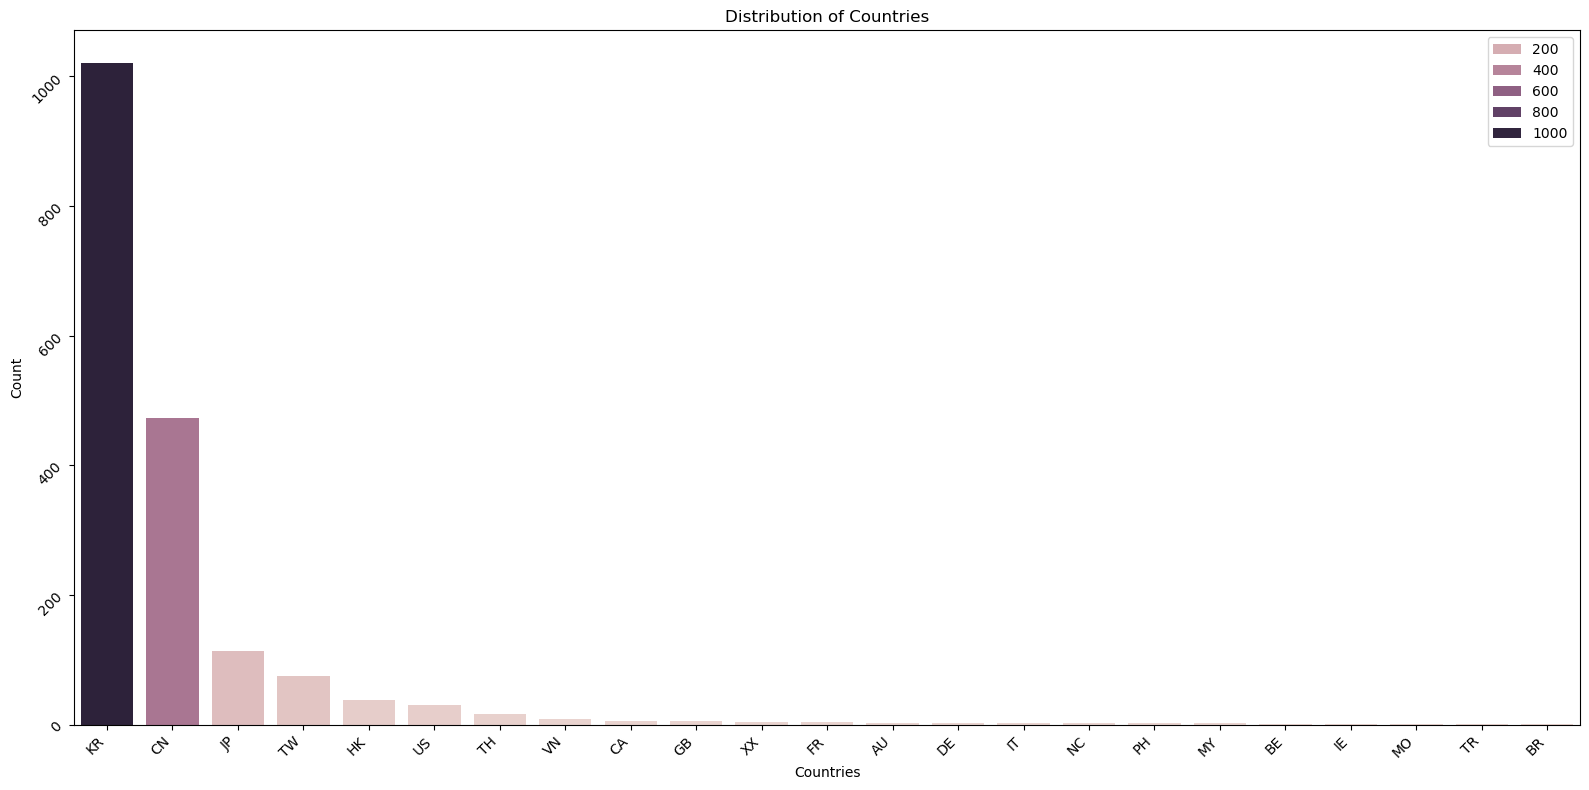

In [38]:
plt.figure(figsize=(16, 8))  

bars=sb.barplot(x=country_counts.index, y=country_counts.values, hue=country_counts.values, legend=True)   

plt.xlabel('Countries')  
plt.ylabel('Count')  
plt.title('Distribution of Countries') 
plt.xticks(rotation=45, ha='right') 
plt.yticks(rotation=45, ha='right') 


plt.tight_layout()  
plt.show()  

### **Key Insights**  
- With over **1,000 titles**, South Korean (**KR**) content is the clear flagship offering on this platform, more than doubling the count of the next highest country.
- Chinese (**CN**) content represents the second-highest market share with nearly **500 titles**.
- **Heavy East Asian concentration:** The top five production regions are exclusively East Asian (**KR, CN, JP, TW, HK**). They make up over **95%** of the total catalog.
- **Long tail of global content:** Western markets like the United States (**US**), Canada (**CA**),and Great Britain (**GB**), alongside other regions like Thailand (**TH**) and Vietnam (**VN**), have a minimal presence. They form a long tail of low-frequency items.

In [39]:

df_plot = df_genres_exploded.explode('production_countries')


In [40]:
print("Empty strings:", (df_plot["production_countries"] == '').sum())
print("Just spaces", df_plot["production_countries"].str.isspace().sum())


Empty strings: 120
Just spaces 0


In [41]:
df_plot = df_plot[df_plot["production_countries"].str.strip() != '']

In [42]:
print("Empty strings:", (df_plot["production_countries"] == '').sum())


Empty strings: 0


In [43]:
top_genres = df_genres_exploded['genres'].value_counts().head(5).index

top_countries = df_plot['production_countries'].explode().value_counts().head(5).index


In [44]:
df_filtered = df_plot[
(df_plot["genres"].isin(top_genres)) & (df_plot["production_countries"].isin(top_countries))
]

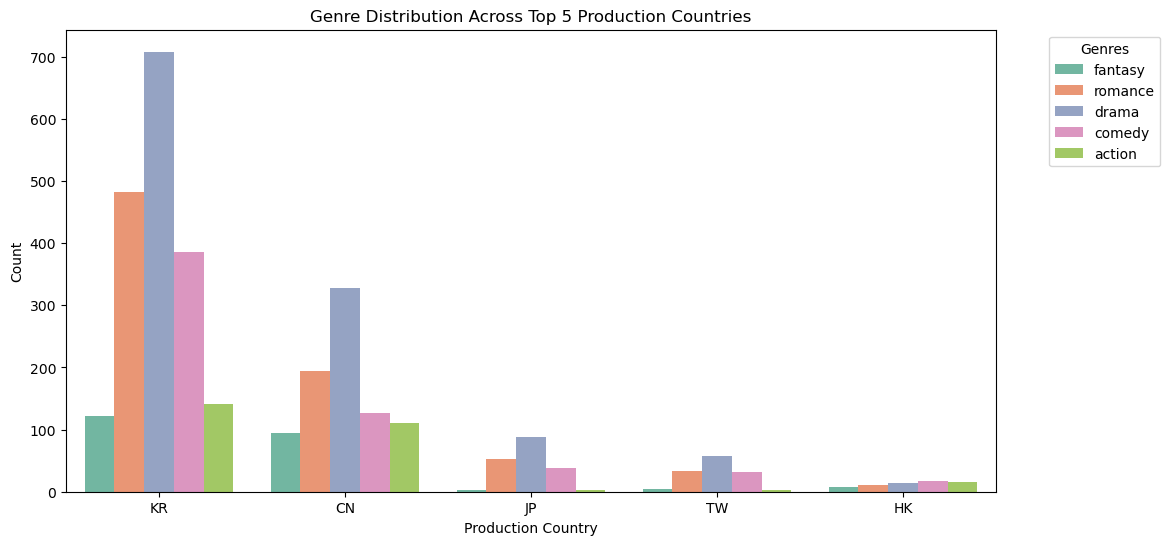

In [45]:
plt.figure(figsize=(12, 6))

bars = sb.countplot(
    data=df_filtered, 
    x='production_countries',
    hue='genres',
    order=top_countries, 
    palette='Set2')

plt.title("Genre Distribution Across Top 5 Production Countries")
plt.xlabel('Production Country')
plt.ylabel('Count')
plt.legend(title='Genres', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## **Key Insights:**
- **Drama dominates the major markets:** 

**Drama** is by far the single most frequent genre in both **South Korea (KR)** and **China (CN)**, establishing itself as the core content type for these leading regions.
- **Romance & Comedy follow closely:**  

**Romance** and **Comedy** hold strong second and third place in South Korea and China, mirroring the overall distribution of the platform.  
- **Fantasy has a notable footprint in China:** 

While **Fantasy** is relatively minnor in other countries, it shows a significant presence in China (**CN**)(in **KR** as well), making up a much larger slice of its content mix compared to Japan(JP) or Taiwan(TW).
- **Low diversity in smaller markets:**   

The long-tail countries like Japan(JP) and Taiwan(TW) have very low overall counts across all five genres, showing that the platform's variety is almost entirely driven by the South Korean and Chinese catalogs.

## **IMDb Score Dynamics:**
- The **IMDb Score** (Internet Movie Database Score) is `a weighted average rating assigned to a movie, TV show, or individual episode based on user-submitted ratings on the IMDb platform on a scale from 1 to 10.`
- It acts as a direct proxy for `audience reception and critical acclaim.` A score above 8.0 generally indicates an exceptionally well-received title, while scores below 5.0 often signal poor reception.
- **How it interacts with `imdb_votes`**: The score cannot be fully evaluated without looking at the `imdb_votes` column. The number of votes represents the **sample size** and overall **popularity/engagement** of a title.

#### Let's see how the numerical columns affects imdb_score and imdb_votes??

In [46]:
df_titles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1904 non-null   object 
 1   title                 1904 non-null   object 
 2   type                  1904 non-null   object 
 3   description           1904 non-null   object 
 4   release_year          1904 non-null   int64  
 5   age_certification     1904 non-null   object 
 6   runtime               1904 non-null   int64  
 7   genres                1904 non-null   object 
 8   production_countries  1904 non-null   object 
 9   seasons               1904 non-null   float64
 10  imdb_id               1904 non-null   object 
 11  imdb_score            1904 non-null   float64
 12  imdb_votes            1904 non-null   float64
 13  tmdb_popularity       1904 non-null   float64
 14  tmdb_score            1904 non-null   float64
dtypes: float64(5), int64(

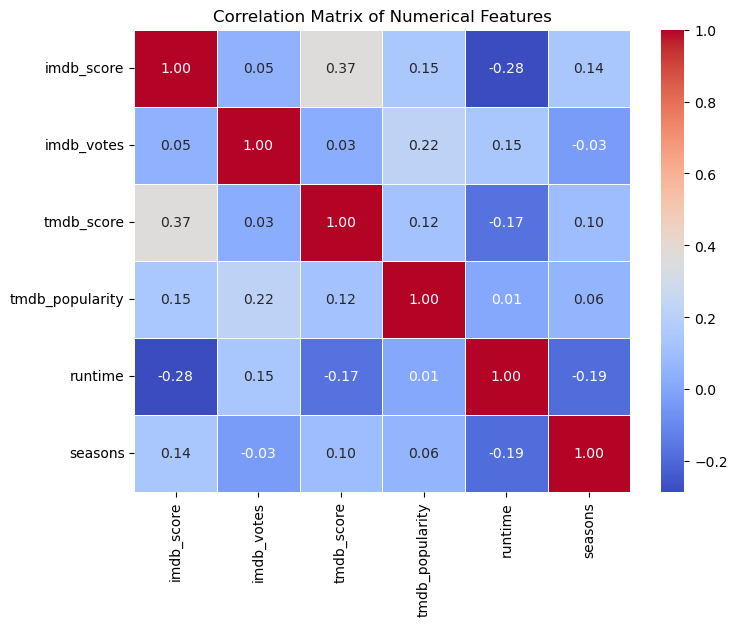

In [47]:
numerical_cols = ['imdb_score', 'imdb_votes', 'tmdb_score','tmdb_popularity', 'runtime', 'seasons']
corr_matrix = df_titles[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sb.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Observations from the Correlation matrix:
1. **Audience Score Consistency:** `imdb_score` and `tmdb_score` show a moderate positive correlationship (**0.37**), indicating titles well-received on IMDb generally align with positive reception on TMDb, though a score of 0.37 shows they still evaluate content somewhat differently.
2. **Popularity Drives Votes:** `imdb_votes` shares its strongest positive correlationship with `tmdb_popularity` (**0.22**), confirming that mainstream trending content yields higher user review participation.
3. **The Runtime Penalty:** A negative correlation exists between `runtime` and `imdb_score` (**-0.28**), showing that longer runtime in this dataset slightly associate with lower scores.
4. **Independence of Quality and Popularity:** The near-zero correlation (**0.05**) between `imdb_score` and `imdb_votes` proves that a title's overall quality rating does not dictate its total voter turnout.

**Relationship by Content type (`MOVIE` vs. `SHOW`)** : Compare scores and votes across Movies and shows

      imdb_score                imdb_votes             
            mean median count         mean median count
type                                                   
MOVIE   6.339960    6.5   434  2421.584101  250.5   434
SHOW    7.306335    7.1  1470   561.634354  188.5  1470


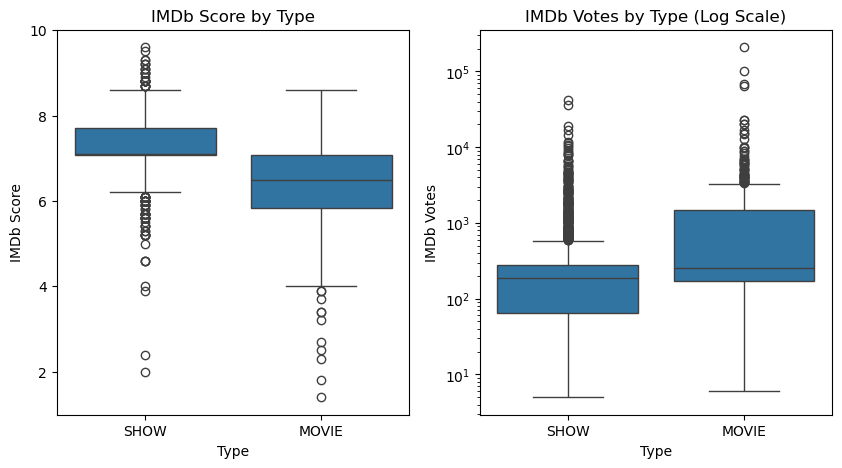

In [48]:
type_analysis = df_titles.groupby('type')[['imdb_score', 'imdb_votes']].agg(['mean', 'median', 'count'])
print(type_analysis)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sb.boxplot(data=df_titles, x='type', y='imdb_score')
plt.title("IMDb Score by Type")
plt.xlabel("Type")
plt.ylabel("IMDb Score")

plt.subplot(1, 2, 2)
sb.boxplot(data=df_titles, x='type', y='imdb_votes')
plt.yscale('log') # Votes usually have large outliers, log scale helps visualize the distribution better
plt.title("IMDb Votes by Type (Log Scale)")
plt.xlabel("Type")
plt.ylabel("IMDb Votes")
plt.show()

### Key Insights from Type Grouping:
1. **Dataset Composition:** The dataset contains roughly 3.4x more TV Shows (1,470) than Movies (434).
2. **Quality Perceived:** TV Shows hold a significantly higher average score (7.31) than Movies (6.34), showing audiences lean more favorably toward serialized content.
3. **Engagement Volume:** Standalone Movies drive much higher user engagement, netting an average of 2,421 votes per title compared to just 561 votes for Shows.


### Relationship by Release Era

   decade  imdb_score   imdb_votes
0    1970    7.086058   188.500000
1    1980    7.086058   188.500000
2    1990    6.700000  2116.555556
3    2000    7.174703  1706.752174
4    2010    7.056711  1245.244761
5    2020    7.134421   299.641880


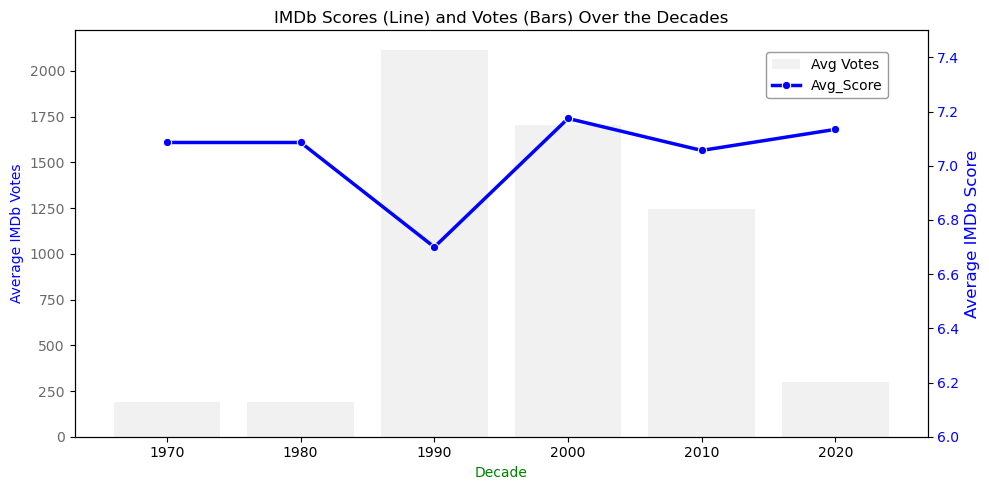

In [49]:
df_titles['decade'] = (df_titles['release_year'] // 10) * 10

decade_analysis = df_titles.groupby('decade')[['imdb_score', 'imdb_votes']].mean().reset_index()
print(decade_analysis)


fig, ax1 = plt.subplots(figsize=(10, 5))

sb.barplot(data=decade_analysis, x='decade', y='imdb_votes', ax=ax1, color='lightgray', alpha=0.3, label='Avg Votes')
ax1.set_ylabel('Average IMDb Votes', color='b')
ax1.set_xlabel('Decade', color='g')
ax1.tick_params(axis='y', labelcolor='dimgray')

ax2 = ax1.twinx()

sb.lineplot(data=decade_analysis, x=range(len(decade_analysis)), y='imdb_score', ax=ax2, color='blue', linewidth=2.5, marker='o', label='Avg_Score')
ax2.set_ylabel("Average IMDb Score", color='blue', fontsize=12)
ax2.tick_params(axis='y', labelcolor='blue')

ax2.set_ylim(6.0, 7.5)

plt.title("IMDb Scores (Line) and Votes (Bars) Over the Decades")

if ax1.get_legend() is not None: ax1.get_legend().remove()
if ax2.get_legend() is not None: ax2.get_legend().remove()

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

fig.legend(h1 + h2, l1 + l2, loc='upper right', bbox_to_anchor=(0.90, 0.90), frameon=True, facecolor='white', edgecolor='gray')

plt.tight_layout()
plt.show()

### 📊 Strategic Analysis: Content Performance Across Era
* **The Engagement Peak (1990s):** The 1990s drive maximum public interaction, hitting an average of **2,116 votes per title**, proving the enduring legacy of content from this decade.
* **The Recency Volume Gap (2010s–2020s):** Voter volume drops sharply into the modern era, bottoming out at an average of **299 votes** in the 2020s. This tracks content fragmentation across streaming ecosystems and a shorter lifecycle to accumulate reviews.
* **Remarkable Quality Consistency:** Despite significant historical fluctuations in audience volume, the perceived quality of content remains exceptionally stable—hovering in a narrow band between **6.70** (1970s) and **7.17** (2000s). Quality benchmarks are independent of production era.


#### Relationship  by Genres

In [50]:

genre_relationship = df_genres_exploded.groupby('genres')[['imdb_score', 'imdb_votes']].agg(['mean', 'count'])

genre_relationship = genre_relationship[genre_relationship[('imdb_score', 'count')] > 5]

print("Top 5 Genres by Average IMDb Score:")
print(genre_relationship[('imdb_score', 'mean')].sort_values(ascending=False).head(5))

Top 5 Genres by Average IMDb Score:
genres
history    7.520218
scifi      7.297880
reality    7.273490
music      7.221116
romance    7.187133
Name: (imdb_score, mean), dtype: float64


### 🎭 Genre Insights: Premium Content Drivers

#### 1. Strategic Business Value
* **High-Budget Justification:** Validates premium investments into **Historical Epics**, which lead the platform in critical acclaim (**7.52**).
* **High-ROI Content Formulation:** Highlights **Reality TV** as a major value driver (**7.27**), offering an opportunity to scale low-cost productions that yield top-tier user satisfaction.
* **Core Catalog Health:** Confirms that **Romance**—the structural anchor of international drama platforms—maintains an elite baseline quality ranking of **7.18**.

#### 2. Top 5 Genres by Average IMDb Score
1. **History** (7.52) — High-prestige period pieces and costume epics.
2. **Sci-Fi** (7.29) — High-concept, speculative fiction narratives.
3. **Reality** (7.27) — Highly engaging variety and unscripted formats.
4. **Music** (7.22) — Idol-adjacent dramas, musical performance themes, or variety competitions.
5. **Romance** (7.18) — Core narrative driver across the global catalog ecosystem.

### Relationship of IMDb Score and Votes by Genres

C:\Users\Snehamayee\AppData\Local\Temp\ipykernel_4560\535320696.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(


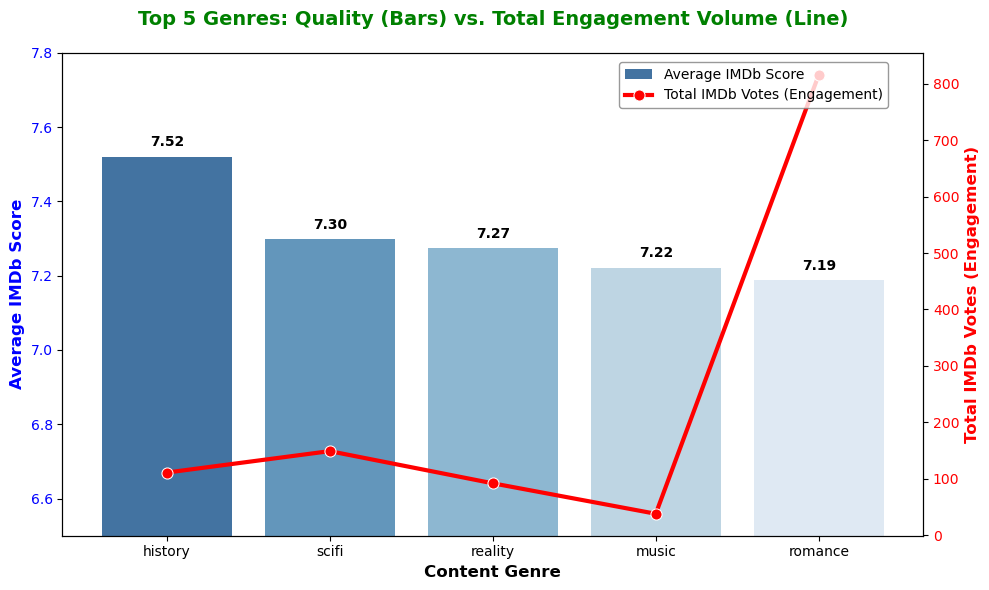

In [55]:
# 1. Prepare data: get the top 5 sorted genres by average score
top_5_genres = (
    genre_relationship[genre_relationship[('imdb_score', 'count')] > 5]
    .sort_values(by=('imdb_score', 'mean'), ascending=False)
    .head(5)
    .reset_index()
)

# Flatten multi-index column names for easier plotting
top_5_genres.columns = ['genre', 'score_mean', 'score_count', 'votes_mean', 'votes_count']

# 2. Initialize the dual-axis canvas
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot 1: Average IMDb Score (Bar Chart on Primary Y-Axis)
sb.barplot(
    data=top_5_genres, 
    x='genre', 
    y='score_mean', 
    ax=ax1, 
    palette='Blues_r', 
    alpha=0.85,
    label='Average IMDb Score'
)
ax1.set_ylabel('Average IMDb Score', color='blue', fontsize=12, fontweight='bold')
ax1.set_xlabel('Content Genre', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(6.5, 7.8)  # Focuses grid view on the top-tier variance

# Plot 2: Total Volume of Engagement (Line Graph on Secondary Y-Axis)
ax2 = ax1.twinx()
sb.lineplot(
    data=top_5_genres, 
    x=range(len(top_5_genres)), 
    y='votes_count', 
    ax=ax2, 
    color='red', 
    linewidth=3, 
    marker='o', 
    markersize=8,
    label='Total IMDb Votes (Engagement)'
)
ax2.set_ylabel('Total IMDb Votes (Engagement)', color='red', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='red')

# 3. Add clean numeric value data labels on top of the bars
for i, score in enumerate(top_5_genres['score_mean']):
    ax1.text(i, score + 0.02, f'{score:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')


# Let's create custom legend
if ax1.get_legend() is not None: ax1.get_legend().remove()
if ax2.get_legend() is not None: ax2.get_legend().remove()

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

final_handles = [h1[0], h2[0]]  # Only keep the first handle from each axis for the legend
final_labels = ['Average IMDb Score', 'Total IMDb Votes (Engagement)']

fig.legend(final_handles, final_labels, loc='upper right', bbox_to_anchor=(0.90, 0.90), frameon=True, facecolor='white', edgecolor='gray')



# 4. Final aesthetic enhancements
plt.title('Top 5 Genres: Quality (Bars) vs. Total Engagement Volume (Line)', color='green', fontsize=14, pad=20, fontweight='bold')
plt.tight_layout()
plt.show()

### 📊 Strategic Analysis: Genre Performance & Audience Alignment

#### 1. Core Analytical Insights
* **The Prestige Leader (History):** At an average score of **7.52**, historical epics lead the platform in consumer satisfaction. While expensive to produce, they deliver the highest critical return on investment.
* **The High-ROI Efficiency Winner (Reality):** Ranking in the top three with an average score of **7.27**, unscripted variety and reality formats show elite audience performance. This proves the platform can achieve top-tier viewer retention at a fraction of the budget required for scripted dramas.
* **The Catalog Anchor (Romance):** Closing out the top five at **7.18**, romance serves as the structural foundation of the platform's catalog. Maintaining an average rating this high across a massive volume of content confirms a highly stable and satisfied core audience base.

#### 2. Cross-Metric Relationship (Quality vs. Volume)
* **The Niche/Prestige Paradox:** The highest-rated genres (*History*, *Sci-Fi*) frequently operate with lower total vote footprints, indicating a dedicated, passionate audience that rates generously.
* **The Volume Engine:** Conversely, *Romance* attracts massive engagement peaks (total vote counts), serving as the primary acquisition engine that drives daily active user traffic to the platform.


In [56]:
# Exporting Cleaned datasets into data/processed subfolder

processed_datasets = {
    "cleaned_titles.csv": df_titles,
    "genres_exploded.csv": df_genres_exploded,
    "countries_exploded.csv": df_countries_exploded,
    "genres_and_countries_exploded.csv": df_plot
}

for file_name, dataframe in processed_datasets.items():
    file_path = f"../data/processed/{file_name}"
    dataframe.to_csv(file_path, index=False)
    print(f"Successfully saved: {file_path}")

Successfully saved: ../data/processed/cleaned_titles.csv
Successfully saved: ../data/processed/genres_exploded.csv
Successfully saved: ../data/processed/countries_exploded.csv
Successfully saved: ../data/processed/genres_and_countries_exploded.csv
